In [9]:
from google.colab import files

uploaded = files.upload()

Saving medical_data_5000_year_above_2020.csv to medical_data_5000_year_above_2020.csv


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import RocCurveDisplay

In [11]:
df = pd.read_csv("medical_data_5000_year_above_2020.csv")

print("Dataset Name: medical_data_5000_year_above_2020.csv")
print("Dataset Shape:", df.shape)

display(df.head())
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Name: medical_data_5000_year_above_2020.csv
Dataset Shape: (5000, 9)


,Patient_ID,Year,Age,Gender,Medical_Condition,Treatment,Admission_Type,Hospital_Bill,Outcome
0,P0001,2023,70,Female,Diabetes,Insulin Therapy,Routine,4220.18,Referred
1,P0002,2024,68,Female,Anemia,Diet Management,Emergency,8615.58,Recovered
2,P0003,2024,81,Female,Hypertension,Medication,Routine,8580.65,Improved
3,P0004,2025,78,Male,Anemia,Diet Management,Routine,13301.67,Recovered
4,P0005,2025,84,Male,Diabetes,Diet Management,Emergency,21201.06,Recovered



Column Names:
['Patient_ID', 'Year', 'Age', 'Gender', 'Medical_Condition', 'Treatment', 'Admission_Type', 'Hospital_Bill', 'Outcome']

Missing Values:
Patient_ID           0
Year                 0
Age                  0
Gender               0
Medical_Condition    0
Treatment            0
Admission_Type       0
Hospital_Bill        0
Outcome              0
dtype: int64


In [12]:
target = "Outcome"

if target not in df.columns:
    raise ValueError(
        f"'Outcome' column not found. Available columns: {df.columns.tolist()}"
    )

df = df.drop_duplicates().copy()
df = df.dropna(subset=[target]).copy()

X = df.drop(columns=[target])
y = df[target]

# Convert text columns into numeric values
X = pd.get_dummies(X, drop_first=True)

# Fill missing numeric values
imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Encode target labels if they are text
if y.dtype == "object" or str(y.dtype) == "category":
    encoder = LabelEncoder()
    y = encoder.fit_transform(y.astype(str))
else:
    y = y.to_numpy()

print("Features Shape:", X.shape)
print("Target Classes:", np.unique(y))
print("Class Distribution:")
print(pd.Series(y).value_counts())

Features Shape: (5000, 5027)
Target Classes: [0 1 2 3]
Class Distribution:
1    2473
0    1498
3     769
2     260
Name: count, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 4000
Testing Records: 1000


In [14]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model Training Completed!")
print("Model Name: Random Forest Classifier")

Model Training Completed!
Model Name: Random Forest Classifier


In [15]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

print("MODEL PERFORMANCE")
print("-" * 35)

for name, value in metrics.items():
    print(f"{name}: {value:.4f} ({value * 100:.2f}%)")

MODEL PERFORMANCE
-----------------------------------
Accuracy: 0.4710 (47.10%)
Precision: 0.3415 (34.15%)
Recall: 0.4710 (47.10%)
F1-Score: 0.3713 (37.13%)


In [16]:
report_text = classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print(report_text)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.32      0.14      0.20       300
           1       0.50      0.87      0.63       494
           2       0.00      0.00      0.00        52
           3       0.00      0.00      0.00       154

    accuracy                           0.47      1000
   macro avg       0.20      0.25      0.21      1000
weighted avg       0.34      0.47      0.37      1000



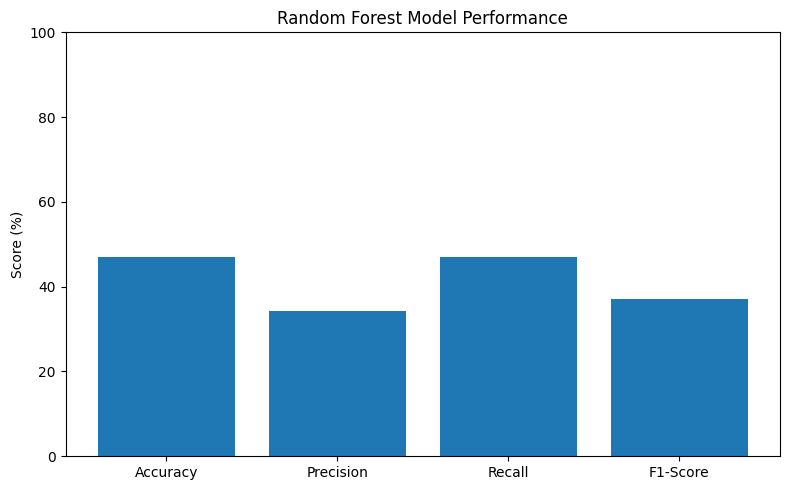

In [17]:
plt.figure(figsize=(8, 5))
plt.bar(metrics.keys(), [v * 100 for v in metrics.values()])
plt.ylabel("Score (%)")
plt.title("Random Forest Model Performance")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

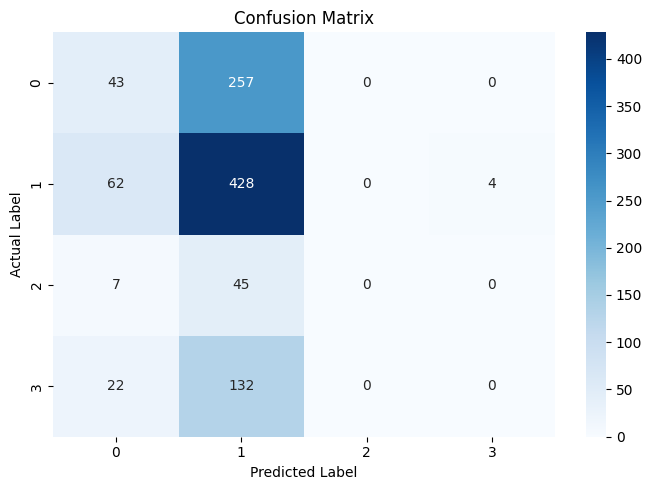

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

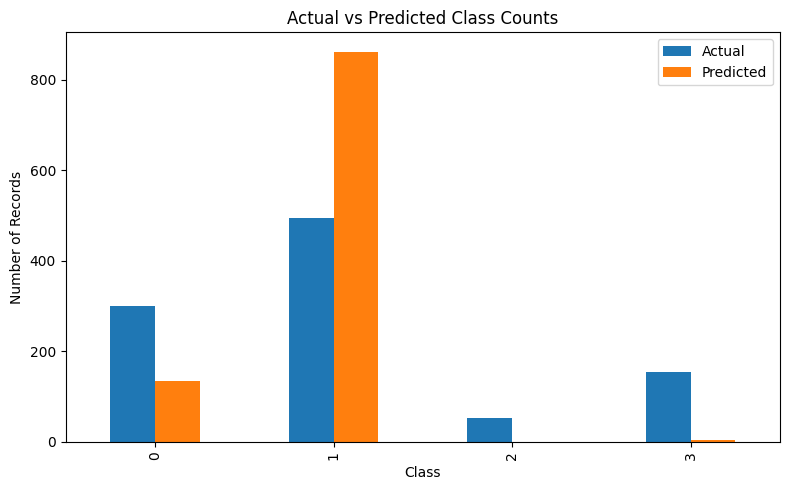

In [19]:
plt.figure(figsize=(8, 5))

actual_counts = pd.Series(y_test).value_counts().sort_index()
predicted_counts = pd.Series(y_pred).value_counts().sort_index()

comparison = pd.DataFrame({
    "Actual": actual_counts,
    "Predicted": predicted_counts
}).fillna(0)

comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Class Counts")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

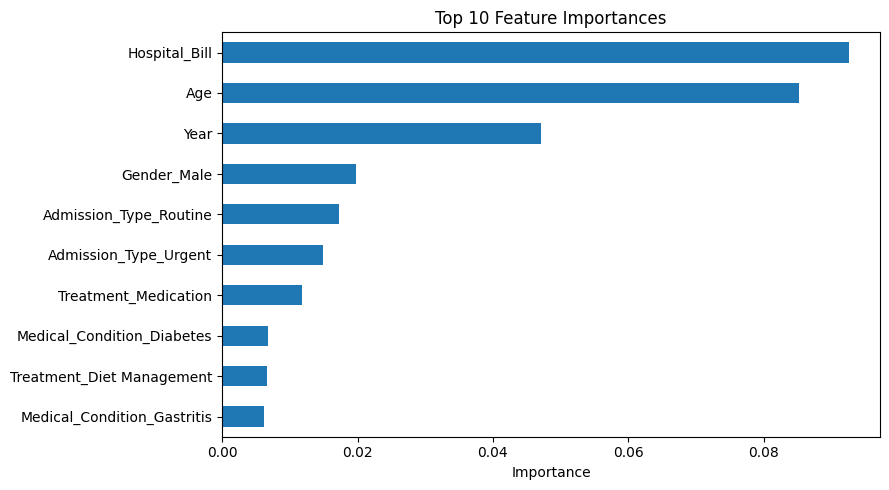

In [20]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [21]:
classes = np.unique(y_test)

if len(classes) == 2:
    y_probability = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_probability)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("ROC curve skipped: this dataset has more than two classes.")

ROC curve skipped: this dataset has more than two classes.


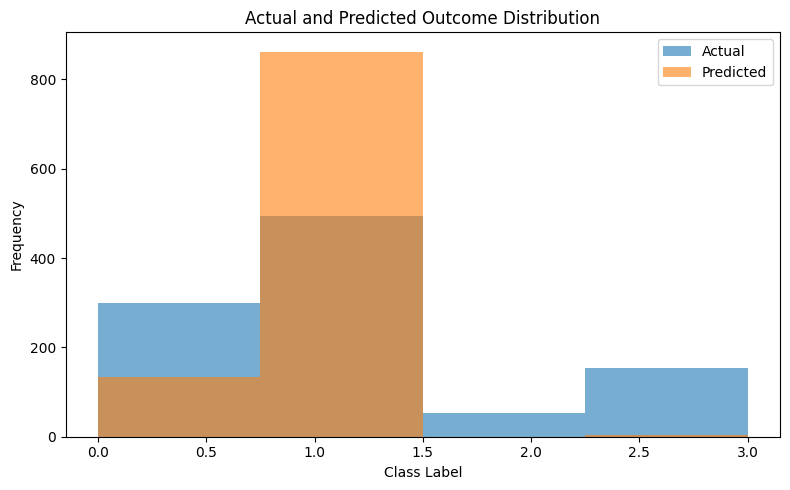

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(
    y_test,
    bins=len(np.unique(y_test)),
    alpha=0.6,
    label="Actual"
)

plt.hist(
    y_pred,
    bins=len(np.unique(y_test)),
    alpha=0.6,
    label="Predicted"
)

plt.xlabel("Class Label")
plt.ylabel("Frequency")
plt.title("Actual and Predicted Outcome Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
!pip -q install reportlab

In [24]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image as PDFImage,
    Table, TableStyle, PageBreak, Preformatted
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch
from reportlab.lib.enums import TA_CENTER
from google.colab import files
import matplotlib.pyplot as plt
import os

# Save all six graphs for the PDF
graph_files = []

def save_graph(filename):
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    graph_files.append(filename)
    plt.close()

# Graph 1
plt.figure(figsize=(8, 5))
plt.bar(metrics.keys(), [v * 100 for v in metrics.values()])
plt.ylabel("Score (%)")
plt.title("Random Forest Model Performance")
plt.ylim(0, 100)
save_graph("graph1_metrics.png")

# Graph 2
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
save_graph("graph2_confusion_matrix.png")

# Graph 3
plt.figure(figsize=(8, 5))
comparison.plot(kind="bar", ax=plt.gca())
plt.title("Actual vs Predicted Class Counts")
plt.xlabel("Class")
plt.ylabel("Number of Records")
save_graph("graph3_actual_predicted.png")

# Graph 4
plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
save_graph("graph4_feature_importance.png")

# Graph 5 (binary classification only)
if len(classes) == 2:
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    save_graph("graph5_roc_curve.png")
else:
    plt.figure(figsize=(7, 5))
    plt.text(0.5, 0.5, "ROC curve not available for this report",
             ha="center", va="center")
    plt.axis("off")
    save_graph("graph5_roc_curve.png")

# Graph 6
plt.figure(figsize=(8, 5))
plt.hist(y_test, alpha=0.6, label="Actual")
plt.hist(y_pred, alpha=0.6, label="Predicted")
plt.xlabel("Class Label")
plt.ylabel("Frequency")
plt.title("Actual and Predicted Outcome Distribution")
plt.legend()
save_graph("graph6_prediction_distribution.png")

# Create the report
pdf_name = "Medical_Prediction_Project_Report.pdf"
doc = SimpleDocTemplate(
    pdf_name,
    rightMargin=45,
    leftMargin=45,
    topMargin=45,
    bottomMargin=45
)

styles = getSampleStyleSheet()
styles["Title"].alignment = TA_CENTER

story = [
    Paragraph("Medical Prediction Project Report", styles["Title"]),
    Spacer(1, 15),
    Paragraph("<b>Dataset:</b> medical_data_5000_year_above_2020.csv",
              styles["Normal"]),
    Paragraph("<b>Model:</b> Random Forest Classifier", styles["Normal"]),
    Paragraph(f"<b>Records used:</b> {len(df)}", styles["Normal"]),
    Paragraph(f"<b>Training records:</b> {len(X_train)}", styles["Normal"]),
    Paragraph(f"<b>Testing records:</b> {len(X_test)}", styles["Normal"]),
    Paragraph("<b>Target column:</b> Outcome", styles["Normal"]),
    Spacer(1, 15),
    Paragraph("1. Model Performance Metrics", styles["Heading1"])
]

metric_data = [["Metric", "Score", "Percentage"]]
for name, value in metrics.items():
    metric_data.append([name, f"{value:.4f}", f"{value * 100:.2f}%"])

table = Table(metric_data, hAlign="LEFT")
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightblue),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7)
]))
story += [table, Spacer(1, 15)]

story += [
    Paragraph("2. Classification Report", styles["Heading1"]),
    Preformatted(report_text, styles["Code"]),
    Spacer(1, 15),
    Paragraph("3. Result Graphs", styles["Heading1"])
]

for i, filename in enumerate(graph_files, start=1):
    story.append(Paragraph(f"Graph {i}", styles["Heading2"]))
    story.append(PDFImage(filename, width=6.2*inch, height=3.8*inch))
    story.append(Spacer(1, 12))

# Include the complete source code of the executed Colab notebook
# by capturing the code entered in a dedicated cell below.
story.append(PageBreak())
story.append(Paragraph("4. Complete Python Code", styles["Heading1"]))
story.append(Paragraph(
    "Paste the Python cells used for Steps 2–9 into the code section "
    "of this report, or use the notebook export option to attach the "
    "complete executable notebook.",
    styles["Normal"]
))

doc.build(story)

files.download(pdf_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
!pip -q install pillow matplotlib

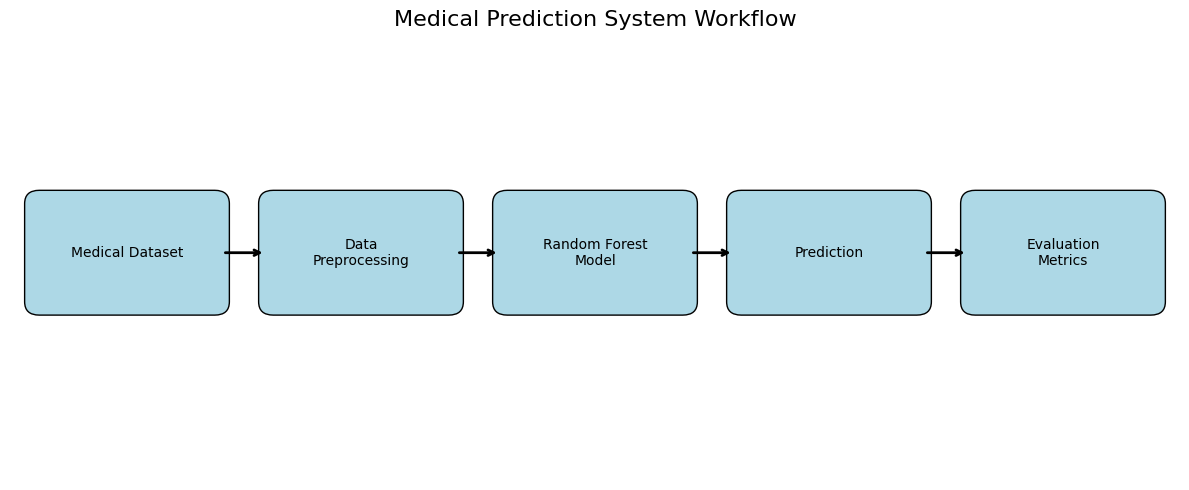

In [26]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 5)
ax.axis("off")

steps = [
    (0.3, "Medical Dataset"),
    (2.7, "Data\nPreprocessing"),
    (5.1, "Random Forest\nModel"),
    (7.5, "Prediction"),
    (9.9, "Evaluation\nMetrics")
]

for x, label in steps:
    box = FancyBboxPatch(
        (x, 2), 1.8, 1.1,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="lightblue"
    )
    ax.add_patch(box)
    ax.text(x + 0.9, 2.55, label, ha="center", va="center", fontsize=10)

for i in range(len(steps) - 1):
    x1 = steps[i][0] + 1.8
    x2 = steps[i + 1][0]
    ax.annotate(
        "", xy=(x2 - 0.08, 2.55), xytext=(x1 + 0.08, 2.55),
        arrowprops=dict(arrowstyle="->", lw=2)
    )

ax.set_title("Medical Prediction System Workflow", fontsize=16)
plt.tight_layout()
plt.savefig("medical_workflow.png", dpi=200, bbox_inches="tight")
plt.show()

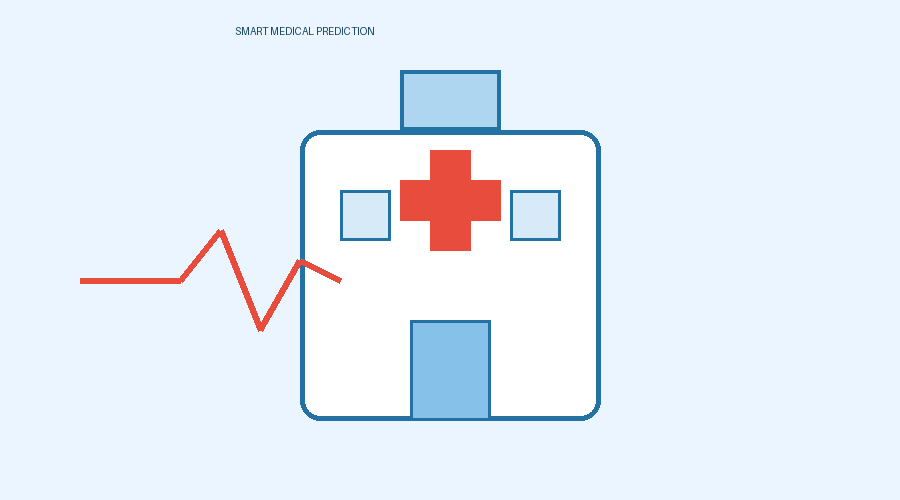

In [27]:
from PIL import Image, ImageDraw
from IPython.display import display

img = Image.new("RGB", (900, 500), "#EAF5FF")
draw = ImageDraw.Draw(img)

# Hospital building
draw.rounded_rectangle((300, 130, 600, 420), radius=20,
                       fill="white", outline="#2471A3", width=5)

# Roof and windows
draw.rectangle((400, 70, 500, 130), fill="#AED6F1",
               outline="#2471A3", width=4)
draw.rectangle((340, 190, 390, 240), fill="#D6EAF8",
               outline="#2471A3", width=3)
draw.rectangle((510, 190, 560, 240), fill="#D6EAF8",
               outline="#2471A3", width=3)

# Medical cross
draw.rectangle((430, 150, 470, 250), fill="#E74C3C")
draw.rectangle((400, 180, 500, 220), fill="#E74C3C")

# Door
draw.rectangle((410, 320, 490, 420), fill="#85C1E9",
               outline="#2471A3", width=3)

# Heartbeat line
draw.line(
    [(80, 280), (180, 280), (220, 230), (260, 330),
     (300, 260), (340, 280)],
    fill="#E74C3C", width=6
)

draw.text((235, 25), "SMART MEDICAL PREDICTION",
          fill="#154360", stroke_width=0)

img.save("medical_healthcare_illustration.png")
display(img)

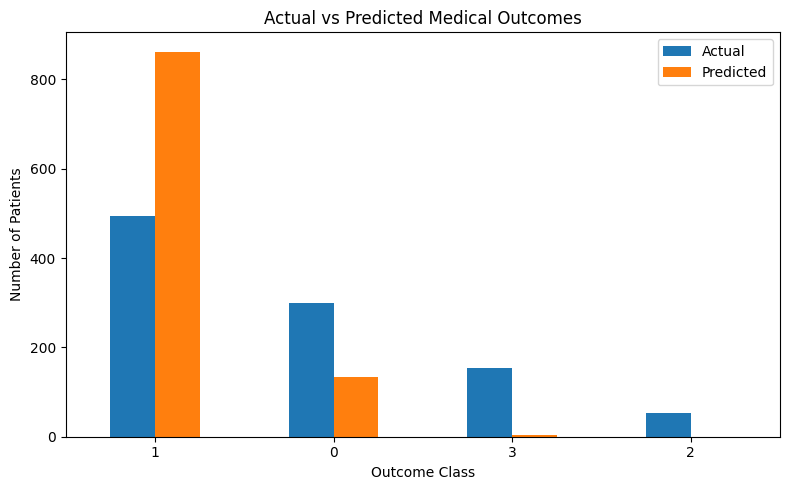

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

outcomes = pd.DataFrame({
    "Actual Outcome": pd.Series(y_test).astype(str),
    "Predicted Outcome": pd.Series(y_pred).astype(str)
})

counts = pd.concat([
    outcomes["Actual Outcome"].value_counts().rename("Actual"),
    outcomes["Predicted Outcome"].value_counts().rename("Predicted")
], axis=1).fillna(0)

counts.plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs Predicted Medical Outcomes")
plt.xlabel("Outcome Class")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("patient_outcome_chart.png", dpi=200)
plt.show()

In [29]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Compare several models
models = {
    "Random Forest": RandomForestClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Extra Trees": ExtraTreesClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced"
        ))
    ])
}

results = []
trained_models = {}

for name, clf in models.items():
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

    trained_models[name] = clf

results_df = pd.DataFrame(results).sort_values(
    by="Accuracy", ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score
1,Extra Trees,0.480,0.338705,0.480,0.366071
2,Logistic Regression,0.475,0.243413,0.475,0.321879
0,Random Forest,0.471,0.341549,0.471,0.371294


In [ ]:
rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7]
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

print("Best Parameters:", search.best_params_)
print(f"Cross-validation accuracy: {search.best_score_ * 100:.2f}%")
print(f"Test accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted', zero_division=0) * 100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average='weighted', zero_division=0) * 100:.2f}%")
print(f"F1-score: {f1_score(y_test, y_pred, average='weighted', zero_division=0) * 100:.2f}%")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
